<a href="https://colab.research.google.com/github/djarosz0201/Python-Projects/blob/main/Python_for_DA_Module_Task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***ETAP 1 - Wstępne zapoznanie się z danymi i ich zawartością***

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
%cd /content/drive/MyDrive/Mate\ Academy\ -\ zadania/Colab-zadania/Zadanie

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

events_data = pd.read_csv("events.csv")
products_data = pd.read_csv("products.csv")
countries_data = pd.read_csv("countries.csv")

Mounted at /content/drive
/content/drive/MyDrive/Mate Academy - zadania/Colab-zadania/Zadanie


In [ ]:
sns.set_theme(style="whitegrid")

In [ ]:
display(events_data)
display(products_data)
display(countries_data)

,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost
0,100640618,10/8/2014,10/18/2014,M,NOR,2103,Online,650.0,205.70,117.11
1,100983083,8/11/2016,8/11/2016,C,SRB,2103,Offline,1993.0,205.70,117.11
2,101025998,7/18/2014,8/11/2014,M,NaN,7940,Online,4693.0,668.27,502.54
3,102230632,5/13/2017,6/13/2017,L,MNE,2455,Online,1171.0,109.28,35.84
4,103435266,8/11/2012,9/18/2012,H,SRB,1270,Offline,7648.0,47.45,31.79
...,...,...,...,...,...,...,...,...,...,...
1325,994504153,1/10/2017,1/13/2017,M,SWE,4594,Online,4734.0,9.33,6.92
1326,994978797,12/5/2014,1/2/2015,H,ITA,1270,Offline,5192.0,47.45,31.79
1327,996754205,9/20/2010,9/22/2010,L,RUS,7331,Offline,574.0,255.28,159.42
1328,998043382,6/15/2010,7/3/2010,H,MLT,8293,Online,2070.0,437.20,263.33


,id,item_type
0,2103,Cereal
1,7940,Household
2,2455,Clothes
3,1270,Beverages
4,8681,Office Supplies
5,4594,Fruits
6,5988,Vegetables
7,7331,Baby Food
8,8875,Meat
9,8293,Cosmetics


,name,alpha-2,alpha-3,region,sub-region
0,Afghanistan,AF,AFG,Asia,Southern Asia
1,Åland Islands,AX,ALA,Europe,Northern Europe
2,Albania,AL,ALB,Europe,Southern Europe
3,Algeria,DZ,DZA,Africa,Northern Africa
4,American Samoa,AS,ASM,Oceania,Polynesia
...,...,...,...,...,...
244,Wallis and Futuna,WF,WLF,Oceania,Polynesia
245,Western Sahara,EH,ESH,Africa,Northern Africa
246,Yemen,YE,YEM,Asia,Western Asia
247,Zambia,ZM,ZMB,Africa,Sub-Saharan Africa


* **events** można połączyć z **products** za pomocą Product ID i id, a **events** z **countries** przez Country Code i alpha-3

In [ ]:
print(events_data.dtypes)
print(products_data.dtypes)
print(countries_data.dtypes)

Order ID            int64
Order Date         object
Ship Date          object
Order Priority     object
Country Code       object
Product ID          int64
Sales Channel      object
Units Sold        float64
Unit Price        float64
Unit Cost         float64
dtype: object
id            int64
item_type    object
dtype: object
name          object
alpha-2       object
alpha-3       object
region        object
sub-region    object
dtype: object


# ***ETAP 2 - Czyszczenie danych***

### **A. Przekształcenie tytułów kolumn**

In [ ]:
dataframes = [events_data, products_data, countries_data]
for df in dataframes:
  df.columns = (df.columns.str.strip().str.lower().str.replace(" ", "_").str.replace("-", "_"))
print(events_data.columns.tolist())
print(products_data.columns.tolist())
print(countries_data.columns.tolist())

['order_id', 'order_date', 'ship_date', 'order_priority', 'country_code', 'product_id', 'sales_channel', 'units_sold', 'unit_price', 'unit_cost']
['id', 'item_type']
['name', 'alpha_2', 'alpha_3', 'region', 'sub_region']


### **B. Analiza brakujących wartości**

In [ ]:
events_data.isna().sum()


,0
order_id,0
order_date,0
ship_date,0
order_priority,0
country_code,82
product_id,0
sales_channel,0
units_sold,2
unit_price,0
unit_cost,0


Braki w **country_code** zastępujemy wartością "Unknown", ponieważ występuje ich dużo, natomiast usuwamy wiersze z brakami w kolumnie **units_sold** ponieważ występuje tylk w 2 wierszach.

In [ ]:
events_data['country_code'] = events_data['country_code'].fillna("Unknown")
events_data = events_data.dropna(subset=['units_sold'])

In [ ]:
products_data.isna().sum()

,0
id,0
item_type,0


### **B. Czyszczenie tekstów - usuwanie spacji**

In [ ]:
for df in dataframes:
  text_cols = df.select_dtypes(include=['object', 'string']).columns
  for col in text_cols:
    df[col] = (df[col].astype(str).str.strip())

### **C. Przekształcanie typów danych**

In [ ]:
events_data = events_data.copy()
events_data['order_date'] = pd.to_datetime(events_data['order_date'], errors='coerce')
events_data['ship_date'] = pd.to_datetime(events_data['ship_date'], errors='coerce')

### **D. Sprawdzenie duplikatów**

In [ ]:
print(events_data.duplicated().sum())
print(products_data.duplicated().sum())
print(countries_data.duplicated().sum())

0
0
0


### **E. Zbadanie anomalii w danych: czy występują ujemne ceny?**

In [ ]:
if 'unit_price' in events_data.columns:
  minus_count = (events_data['unit_price'] < 0).sum()
  print(f"Liczba wartości ujemnych: {minus_count}")

if 'unit_cost' in events_data.columns:
  minus_count = (events_data['unit_cost'] < 0).sum()
  print(f"Liczba wartości ujemnych: {minus_count}")

Liczba wartości ujemnych: 0
Liczba wartości ujemnych: 0


# ***ETAP 3 - Analiza i wizualizacja danych***

### **A. Łączenie tabel**

In [ ]:
data_frame = events_data.merge(products_data, left_on='product_id', right_on="id", how='left')

data_frame = data_frame.merge(countries_data, left_on='country_code', right_on='alpha_3', how='left')

columns_drop = [col for col in ['id', 'alpha_2', 'alpha_3'] if col in data_frame.columns]
data_frame.drop(columns=columns_drop, inplace=True)

data_frame.fillna("Unknown", inplace=True)
data_frame['sales_channel'] = data_frame['sales_channel'].astype(str).str.lower()

display(data_frame)

,order_id,order_date,ship_date,order_priority,country_code,product_id,sales_channel,units_sold,unit_price,unit_cost,item_type,name,region,sub_region
0,100640618,2014-10-08,2014-10-18,M,NOR,2103,online,650.0,205.70,117.11,Cereal,Norway,Europe,Northern Europe
1,100983083,2016-08-11,2016-08-11,C,SRB,2103,offline,1993.0,205.70,117.11,Cereal,Serbia,Europe,Southern Europe
2,101025998,2014-07-18,2014-08-11,M,Unknown,7940,online,4693.0,668.27,502.54,Household,Unknown,Unknown,Unknown
3,102230632,2017-05-13,2017-06-13,L,MNE,2455,online,1171.0,109.28,35.84,Clothes,Montenegro,Europe,Southern Europe
4,103435266,2012-08-11,2012-09-18,H,SRB,1270,offline,7648.0,47.45,31.79,Beverages,Serbia,Europe,Southern Europe
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1323,994504153,2017-01-10,2017-01-13,M,SWE,4594,online,4734.0,9.33,6.92,Fruits,Sweden,Europe,Northern Europe
1324,994978797,2014-12-05,2015-01-02,H,ITA,1270,offline,5192.0,47.45,31.79,Beverages,Italy,Europe,Southern Europe
1325,996754205,2010-09-20,2010-09-22,L,RUS,7331,offline,574.0,255.28,159.42,Baby Food,Russia,Europe,Eastern Europe
1326,998043382,2010-06-15,2010-07-03,H,MLT,8293,online,2070.0,437.20,263.33,Cosmetics,Malta,Europe,Southern Europe


### **B. Obliczenie czasu realizacji zamówienia i cech czasowych do analizy**
### **C. KPI**

In [ ]:
data_frame['totals_revenue'] = (data_frame['units_sold'] * data_frame['unit_price'])
data_frame['totals_cost'] = (data_frame['units_sold'] * data_frame['unit_cost'])
data_frame['totals_profit'] = (data_frame['totals_revenue'] - data_frame['totals_cost'])

total_orders = data_frame['order_id'].nunique()
total_revenue = data_frame['totals_revenue'].sum()
total_profit = data_frame['totals_profit'].sum()

unique_countries = data_frame[data_frame['name'] != "Unknown"]['name'].nunique()

data_frame['profit'] = data_frame['units_sold'] * (data_frame['unit_price'] - data_frame['unit_cost'])
shipping_profit = (data_frame.groupby('shipping_days')['profit'].mean().reset_index())

print(f"Całkowita liczba zamówień: {total_orders}")
print(f"Całkowity przychód: ${total_revenue}")
print(f"Całkowity zysk: ${total_profit}")
print(f"Całkowita liczba krajów: {unique_countries}")

data_frame["order_date"] = pd.to_datetime(data_frame["order_date"])
data_frame["ship_date"] = pd.to_datetime(data_frame["ship_date"])
data_frame["shipping_days"] = (data_frame["ship_date"] - data_frame["order_date"]).dt.days

data_frame["order_year_month"] = data_frame["order_date"].dt.to_period("M")
data_frame["day_of_week"] = data_frame["order_date"].dt.day_name()
data_frame["month_name"] = data_frame["order_date"].dt.month_name()

days_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
data_frame["day_of_week"] = pd.Categorical(data_frame["day_of_week"], categories=days_order, ordered=True)

months_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December',]

data_frame['month_name'] = pd.Categorical(data_frame['order_date'].dt.month_name(), categories=months_order, ordered=True,)

monthly_order = (data_frame.groupby(['order_year_month', 'item_type'])['profit'].sum().reset_index())
monthly_order['order_year_month_dt'] = monthly_order['order_year_month'].dt.to_timestamp()

Całkowita liczba zamówień: 1328
Całkowity przychód: $1702129408.21
Całkowity zysk: $501434459.0
Całkowita liczba krajów: 45


### **D. Analiza sprzedaży i zysku wg kategorii i kanałów sprzedaży i krajów**

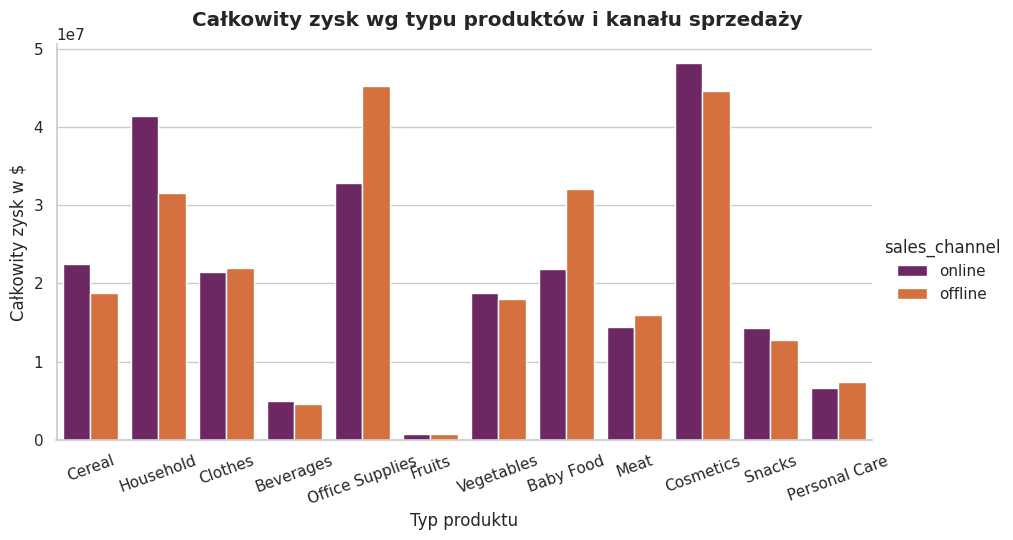

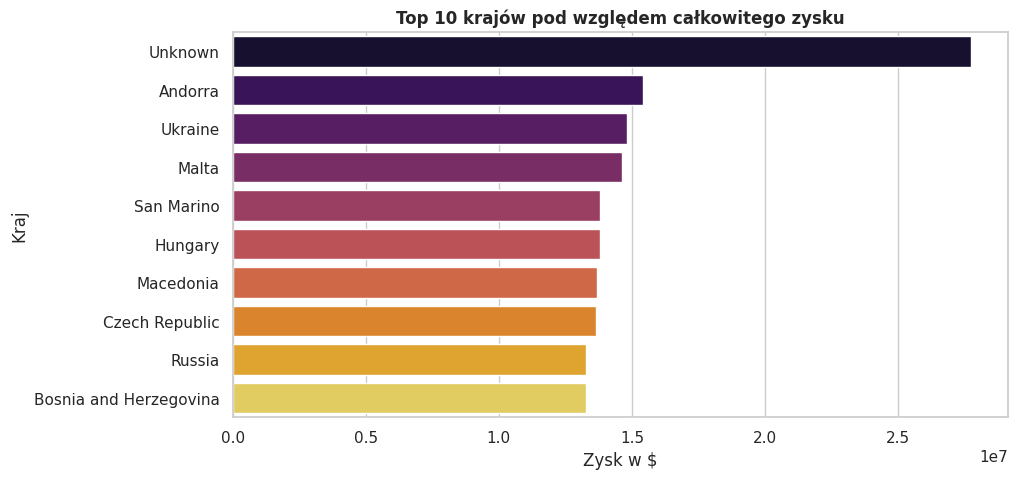

In [ ]:
sales_cat = sns.catplot(data=data_frame, x='item_type', y='profit', hue='sales_channel', kind='bar', estimator='sum', errorbar=None, palette='inferno', height=5, aspect=1.8)
sales_cat.fig.suptitle("Całkowity zysk wg typu produktów i kanału sprzedaży", y=1, fontweight='bold')
sales_cat.set_axis_labels("Typ produktu", "Całkowity zysk w $")
plt.xticks(rotation=20)
plt.show()

top10_countries = (data_frame.groupby('name')['profit'].sum().nlargest(10).reset_index())
plt.figure(figsize=(10, 5))
sns.barplot(data=top10_countries, x='profit', y='name', palette='inferno', hue='name', legend=False)
plt.title("Top 10 krajów pod względem całkowitego zysku", fontweight='bold')
plt.xlabel("Zysk w $")
plt.ylabel("Kraj")
plt.show()

### **E. Analiza czasu wysyłki**

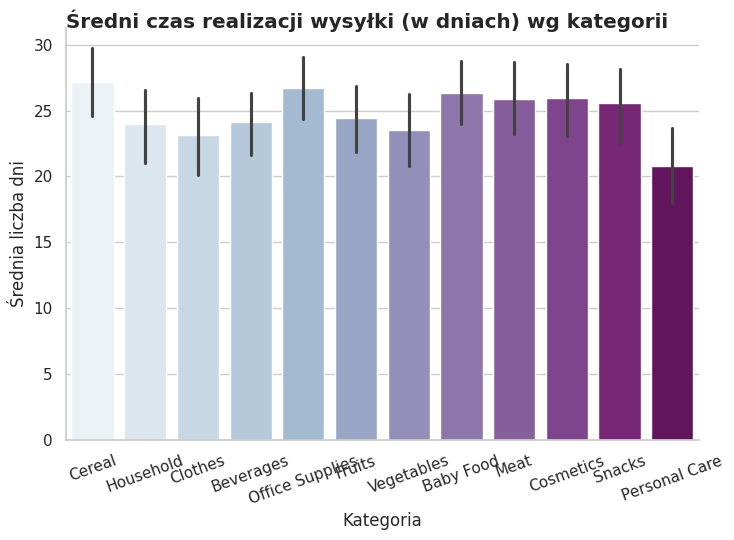

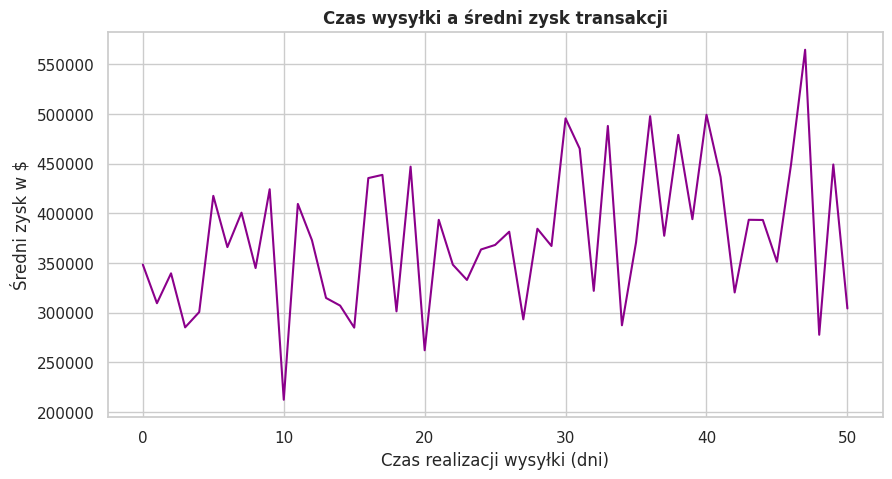

In [ ]:
avg_time = sns.catplot(data=data_frame, x='item_type',y='shipping_days', kind='bar', palette='BuPu', hue='item_type', legend=False, height=5, aspect=1.5)
avg_time.fig.suptitle("Średni czas realizacji wysyłki (w dniach) wg kategorii", y=1, fontweight='bold')
avg_time.set_axis_labels("Kategoria", "Średnia liczba dni")
plt.xticks(rotation=20)
plt.show()

shipping_profit = (data_frame.groupby('shipping_days')['profit'].mean().reset_index())
plt.figure(figsize=(10, 5))
sns.lineplot(data=shipping_profit, x='shipping_days', y='profit', markers='o', color='darkmagenta')
plt.title("Czas wysyłki a średni zysk transakcji", fontweight='bold')
plt.xlabel("Czas realizacji wysyłki (dni)")
plt.ylabel("Średni zysk w $")
plt.show()

###**F. Dynamika w czasie**

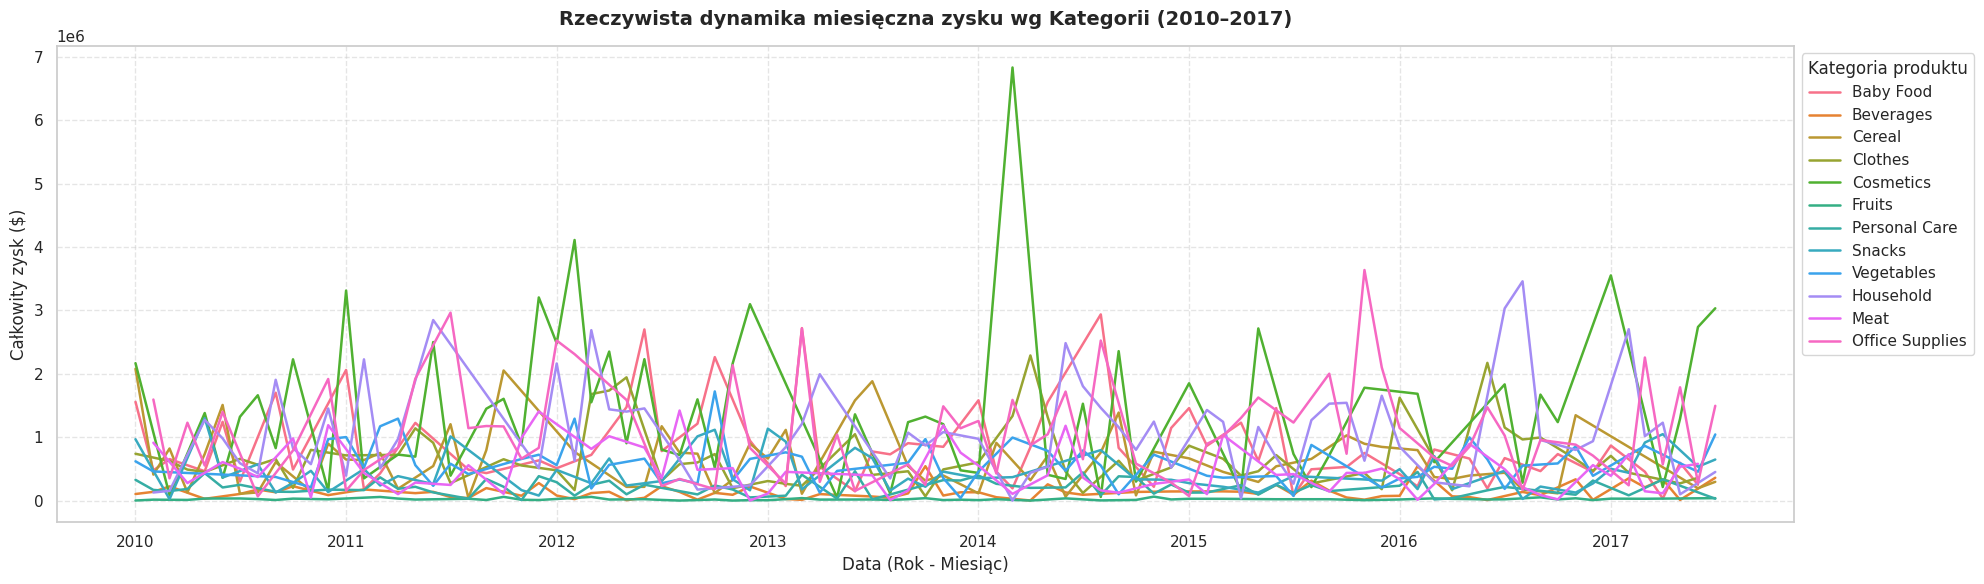

In [ ]:
plt.figure(figsize=(20, 6))
sns.lineplot(data=monthly_order, x='order_year_month_dt', y='profit', hue='item_type', linewidth=1.8,)

plt.title('Rzeczywista dynamika miesięczna zysku wg Kategorii (2010–2017)', fontsize=14, fontweight='bold', pad=15,)
plt.xlabel('Data (Rok - Miesiąc)', fontsize=12)
plt.ylabel('Całkowity zysk ($)', fontsize=12)

plt.legend(title='Kategoria produktu', bbox_to_anchor=(1, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# ***ETAP 4 - Raportowanie***

###**1. Analiza sprzedaży i zysku wg kategorii i kanałów sprzedaży i krajów**
* Najwyższe zyski zarówno w kanale online i offline przynoszą działy **Cosmetics** i **Office Supplies** ze znaczną przewagą nad pozostałymi kategoriami
* Najniższe zyski generują działy **Beverages** i **Fruits**
* Największe zyski generuje region Europa
* W Top10 krajów sprzedaż rozkłada się równomiernie
#### ***Rekomendacja:***
Działania marketingowe i reklamowe należy skupić przede wszystkim na kategoriach wysokomarżowych **(Cosmetics, Household i Office Supplies)**, a produkty szybkozbywalne takie jak **Fruits i Beverages** potraktować jako przyciągające ruch.
###**2. Analiza czasu wysyłki**
* Nie ma wyraźnej korelacji między czasem  realizacji wysyłki a całkowitym zyskiem - co oznacza, że opóźnienia w wysyłce nie mają wpływu na wysokość zysku
* Nie ma również korelacji między czasem wysyłki a kategorią produktu - wykres pokazuje, że średnio wysyłka zajmuje tyle samo niezależnie od kategorii produktu
#### ***Rekomendacja:***
Brak wpływu czasu dostawy na zysk nie oznacza, że problemy logistyczne należy ignorować. Długi czas wysyłki może negatywnie wpływać na wskaźnik ponownych zakupów oraz na oceny klientów. Zaleca się wdrożyć działania usprawniające proces wysyłki i unormowanie go do 5-7 dni.
###**3.  Analiza w czasie**
* Zrównoważony rozkład dzienny - zamóienia w rozbiciu na dni tygodnia rozkładają się równomiernie
* Ze względu na globalny charakter rynku oraz kanał sprzedaży zarówno Online jak i Offline, nie występuje wyraźny spadek ani szczyt w wybrane dni tygodnia
* Ocena sezonowości:
  * Większość kategorii wykazuje stałe zapotrzebowanie przez cały rok
####***Rekomendacja:***
Brak wyraźnej sezonowości większości produktów pozwala na optymalizację zatowarowania magazynów przez cały rok, tak aby skrócić czas wysyłki.

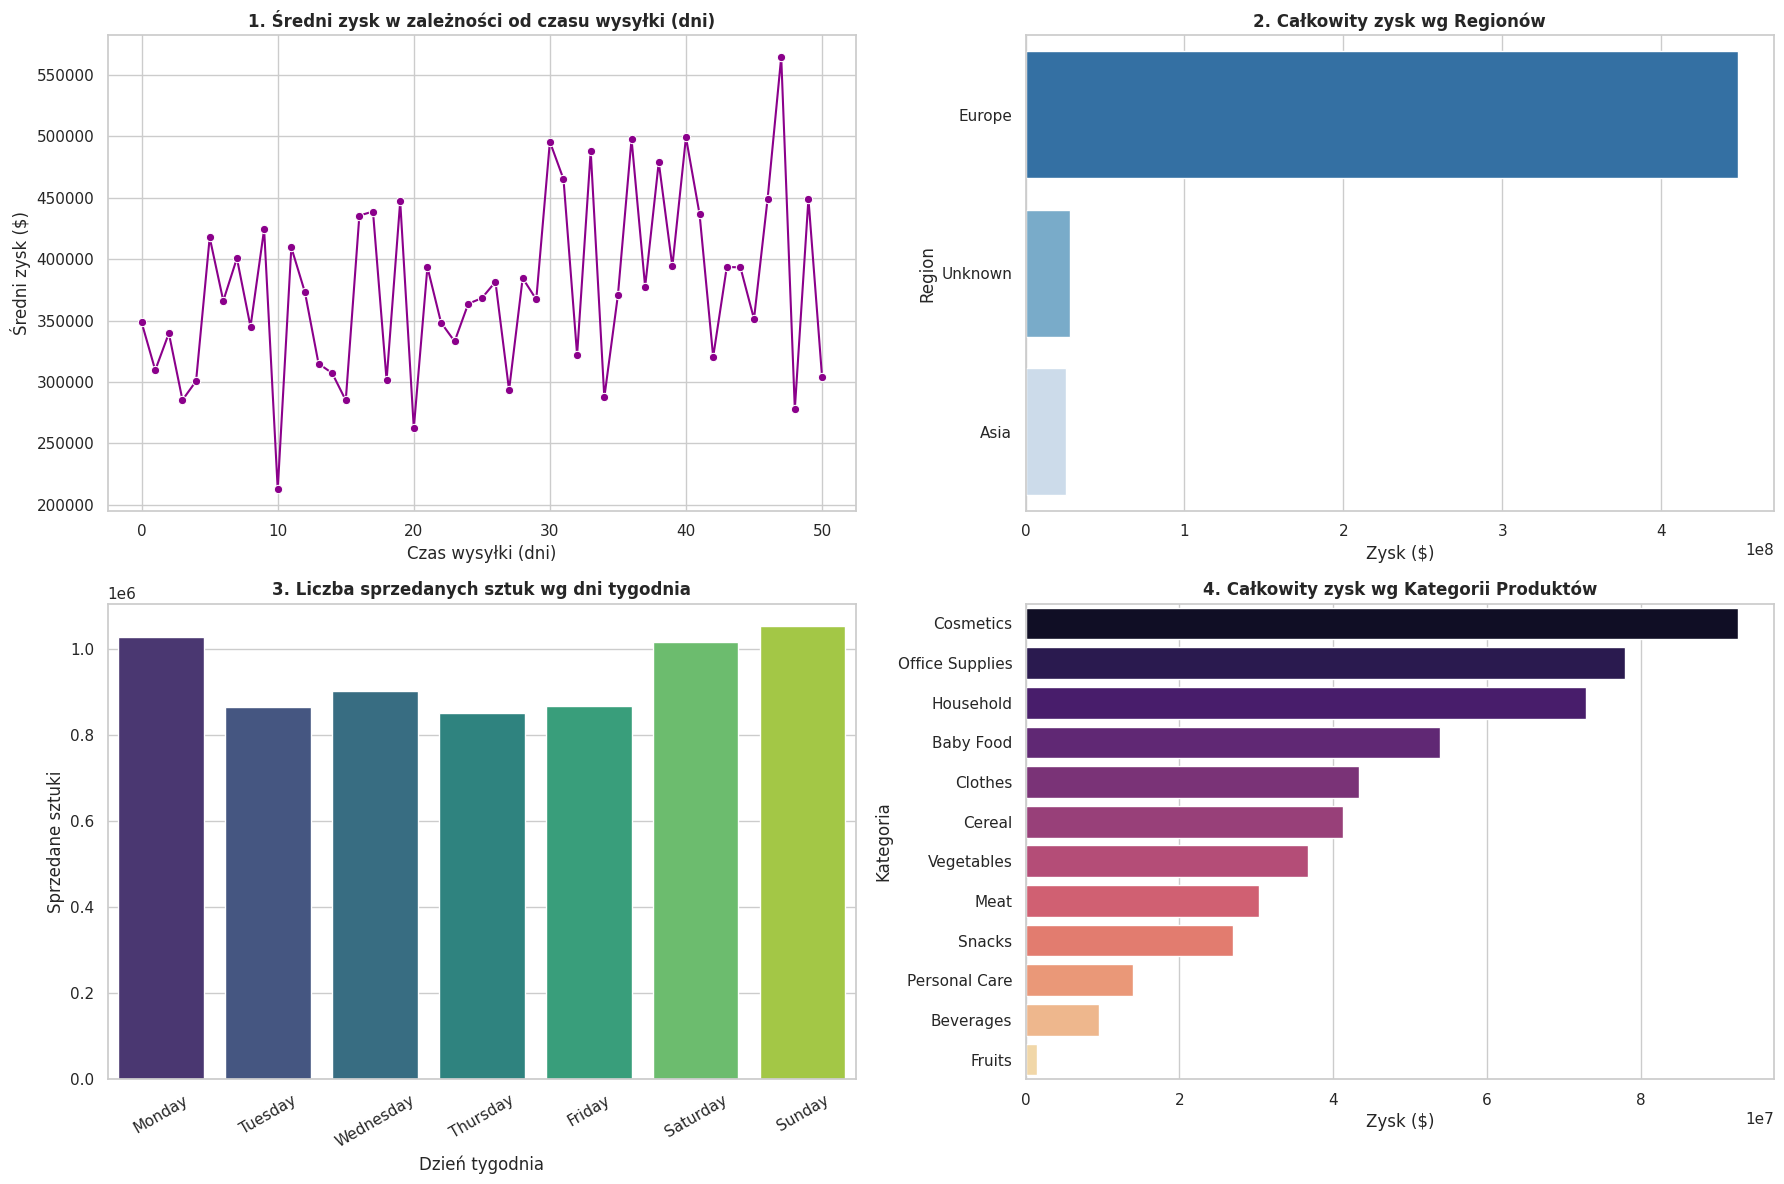

In [ ]:
# @title
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

shipping_profit = (data_frame.groupby("shipping_days")["profit"].mean().reset_index())
sns.lineplot(data=shipping_profit, x="shipping_days", y="profit", ax=axes[0, 0], marker="o", color="darkmagenta")
axes[0, 0].set_title("1. Średni zysk w zależności od czasu wysyłki (dni)", fontweight="bold")
axes[0, 0].set_xlabel("Czas wysyłki (dni)")
axes[0, 0].set_ylabel("Średni zysk ($)")

region_profit = (data_frame.groupby("region")["profit"].sum().reset_index().sort_values(by="profit", ascending=False))
sns.barplot(data=region_profit, x="profit", y="region", ax=axes[0, 1], palette="Blues_r", hue="region", legend=False,)
axes[0, 1].set_title("2. Całkowity zysk wg Regionów", fontweight="bold")
axes[0, 1].set_xlabel("Zysk ($)")
axes[0, 1].set_ylabel("Region")

dow_sales = (data_frame.groupby("day_of_week", observed=False)["units_sold"].sum().reset_index())
sns.barplot(data=dow_sales, x="day_of_week", y="units_sold", ax=axes[1, 0], palette="viridis", hue="day_of_week", legend=False)
axes[1, 0].set_title("3. Liczba sprzedanych sztuk wg dni tygodnia", fontweight="bold")
axes[1, 0].set_xlabel("Dzień tygodnia")
axes[1, 0].set_ylabel("Sprzedane sztuki")
axes[1, 0].tick_params(axis="x", rotation=30)

cat_profit = (data_frame.groupby("item_type")["profit"].sum().reset_index().sort_values(by="profit", ascending=False))
sns.barplot(data=cat_profit, x="profit", y="item_type", ax=axes[1, 1], palette="magma", hue="item_type", legend=False)
axes[1, 1].set_title("4. Całkowity zysk wg Kategorii Produktów", fontweight="bold")
axes[1, 1].set_xlabel("Zysk ($)")
axes[1, 1].set_ylabel("Kategoria")

plt.tight_layout()
plt.show()